<a href="https://colab.research.google.com/github/jatinkumar-creator/machine-learning-portfolio/blob/main/04_Regression_notebooks_05_Polynomial_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Polynomial Regression
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
#Create a nonlinear dataset
np.random.seed(42)

X = np.linspace(0, 10, 100)

y = 2 * X**2 + 3 * X + 5 + np.random.normal(0, 10, 100)

df = pd.DataFrame({
    "Experience": X,
    "Output": y
})

df.head()

,Experience,Output
0,0.00000,9.967142
1,0.10101,3.940793
2,0.20202,12.164570
3,0.30303,21.323044
4,0.40404,4.197085


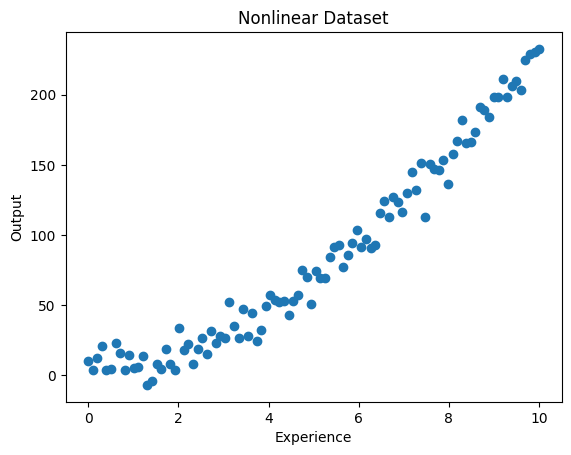

In [3]:
#Visualize the dataset
plt.scatter(X, y)

plt.xlabel("Experience")
plt.ylabel("Output")

plt.title("Nonlinear Dataset")

plt.show()

In [4]:
#Prepare X and y
X = df[["Experience"]]

y = df["Output"]

In [5]:
#Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 80
Testing records: 20


In [6]:
#Train a Linear Regression model
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

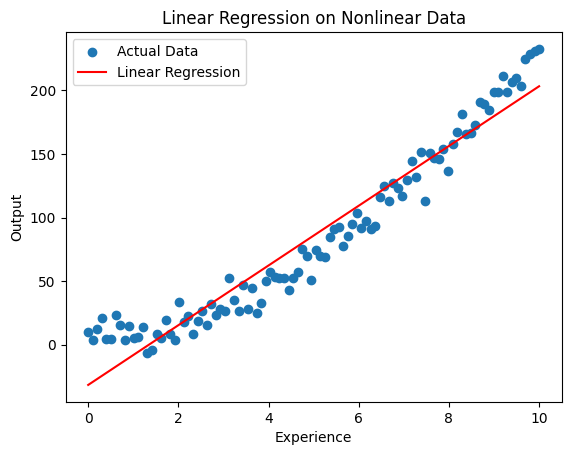

In [7]:
#Visualize Linear Regression
plt.scatter(X, y, label="Actual Data")

plt.plot(
    X,
    linear_model.predict(X),
    color="red",
    label="Linear Regression"
)

plt.xlabel("Experience")
plt.ylabel("Output")

plt.title("Linear Regression on Nonlinear Data")

plt.legend()
plt.show()

In [8]:
#Create Polynomial Features
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)

X_test_poly = poly.transform(X_test)

print("Original features:")
print(X_train.head())

print("\nPolynomial features:")
print(X_train_poly[:5])

Original features:
    Experience
55    5.555556
88    8.888889
26    2.626263
42    4.242424
69    6.969697

Polynomial features:
[[ 1.          5.55555556 30.86419753]
 [ 1.          8.88888889 79.01234568]
 [ 1.          2.62626263  6.89725538]
 [ 1.          4.24242424 17.99816345]
 [ 1.          6.96969697 48.57667585]]


In [9]:
#Train Polynomial Regression
poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train)

poly_predictions = poly_model.predict(X_test_poly)

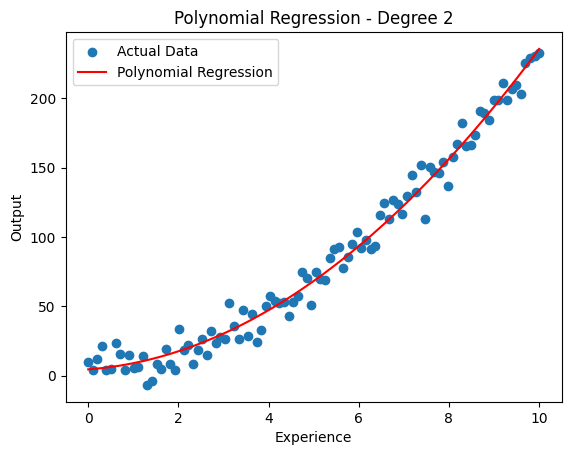

In [10]:
#Visualize Polynomial Regression
X_curve = pd.DataFrame({
    "Experience": np.linspace(0, 10, 200)
})

X_curve_poly = poly.transform(X_curve)

y_curve = poly_model.predict(X_curve_poly)

plt.scatter(X, y, label="Actual Data")

plt.plot(
    X_curve,
    y_curve,
    color="red",
    label="Polynomial Regression"
)

plt.xlabel("Experience")
plt.ylabel("Output")

plt.title("Polynomial Regression - Degree 2")

plt.legend()
plt.show()

In [11]:
#Experiment with different polynomial degrees
degrees = [1, 2, 3, 4, 5]

results = []

for degree in degrees:

    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    results.append({
        "Degree": degree,
        "MAE": mean_absolute_error(
            y_test,
            predictions
        ),
        "MSE": mean_squared_error(
            y_test,
            predictions
        ),
        "R2 Score": r2_score(
            y_test,
            predictions
        )
    })

degree_results = pd.DataFrame(results)

degree_results

,Degree,MAE,MSE,R2 Score
0,1,12.921354,281.106120,0.931359
1,2,6.006415,61.963305,0.984870
2,3,5.831036,60.224716,0.985294
3,4,6.009446,63.488229,0.984497
4,5,6.155970,64.912604,0.984149
